# Energy Pulse: when does a campus building behave differently?
**Dataset:** I-BLEND, IIIT Delhi. 52 months of electricity use for 9 meters plus the institute calendar
(built by `scripts/preprocess_iblend.py`).

The calendar marks **teaching days** and **low-activity days** (weekends, holidays, vacations). It does **not** mark
exams, so this notebook makes no claim about exams.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from campuspulse.energy import pipeline as P
from campuspulse.common import stats_tests
from campuspulse.common.decisions import DecisionLog, defaults, robustness_matrix, heatmap, survival_summary, fragility_table
from campuspulse.common.plots import theme, badge
theme()
raw = P.load_raw()
print(f"{len(raw):,} hours from {raw['datetime'].min()} to {raw['datetime'].max()}")
print("Share of hours with no reading, per meter:")
print(raw[[m for m in P.METERS if m in raw]].isna().mean().round(3).to_string())

38,520 hours from 2013-08-10 00:00:00+05:30 to 2017-12-31 23:00:00+05:30
Share of hours with no reading, per meter:
Academic              0.017
Lecture               0.017
Library               0.256
Mess                  0.126
Facilities            0.105
Boys_main             0.253
Boys_backup           0.249
Girls_main            0.281
Girls_backup          0.003
total_hostel_power    0.354
total_campus_power    0.237


## 1. Cleaning with a log (meter gaps, spikes)

In [2]:
log = DecisionLog()
df = P.clean(defaults(P.DECISIONS), log)
log.to_frame()

## 2. Daily load shape: teaching days vs low-activity days (L3–4)

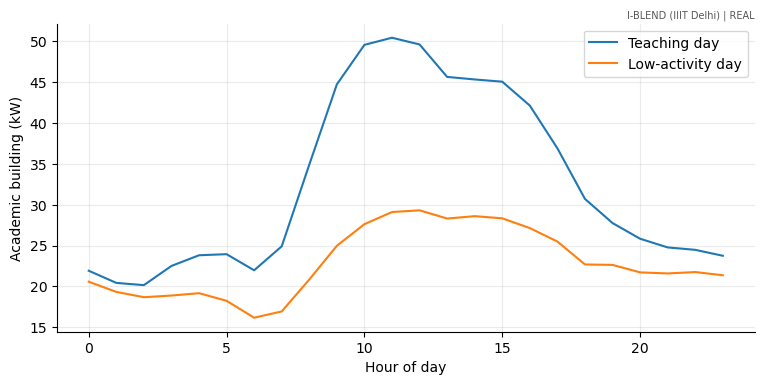

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for flag, label in [(1, "Teaching day"), (0, "Low-activity day")]:
    df[df["is_teaching"] == flag].groupby("hour")["Academic"].mean().div(1000).plot(ax=ax, label=label)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Academic building (kW)"); ax.legend(); badge(ax, "I-BLEND (IIIT Delhi)")
plt.show()

## 3. Hypothesis tests

In [4]:
st = P.run_stats(df)
for name, key in [("Academic building by day, teaching vs low-activity", "teaching_t"),
                  ("Hostels at night, term vs vacation", "term_t")]:
    t = st[key]
    print(f"{name}: diff {t['diff']:+,.0f} W, t = {t['t']:.2f}, p = {t['p']:.2e}, Cohen's d = {t['cohens_d']:.2f}")
    print("   ", stats_tests.conclude(t["p"], name + " differ."))
w = st["within_month_t"]
print(f"Same-month check: {w['n_months']} months, mean diff {w['mean_diff']:+,.0f} W, p = {w['p']:.3f}")
print("   ", stats_tests.conclude(w["p"], "the term effect survives within the same month."))
st["by_month"].round(0)

Academic building by day, teaching vs low-activity: diff +17,858 W, t = 63.21, p = 0.00e+00, Cohen's d = 1.32
    DECISION: reject H0 (p = 0.00e+00 < 0.05). Academic building by day, teaching vs low-activity differ.
Hostels at night, term vs vacation: diff +12,169 W, t = 31.63, p = 7.04e-187, Cohen's d = 0.97
    DECISION: reject H0 (p = 7.04e-187 < 0.05). Hostels at night, term vs vacation differ.
Same-month check: 7 months, mean diff +8,108 W, p = 0.061
    DECISION: fail to reject H0 (p = 6.07e-02 >= 0.05). No evidence for: the term effect survives within the same month.


## 4. Daily profiles: PCA and clustering (L11–L14, L19–21)

In [5]:
dec = P.run_decomposition(df)
print("PCA variance explained:", np.round(dec["pca_variance"], 3))
metrics, profiles = P.run_clustering(df)
print(metrics.round(3).to_string(index=False))
profiles

PCA variance explained: [0.565 0.218 0.095]
method  n_clusters  noise_share  silhouette  davies_bouldin   eps
kmeans           3        0.000       0.408           0.889   NaN
 agglo           3        0.000       0.346           0.876   NaN
dbscan           3        0.049       0.460           0.582 2.632
optics           5        0.866       0.622           0.486   NaN


## 5. Association rules (L18)

In [6]:
P.mine_energy_rules(df).head(10)

## 6. Robustness

{'holds': 14, 'weakens': 1, 'inflates': 0, 'reverses': 0, 'n/a': 0, 'tested': 15, 'survival_rate': 0.9333333333333333}
  finding                            worst_variant change  verdict
0     EN3        meter_gap_imputation=forward_fill  x2.10  fragile
1     EN1                      resample_freq=daily  x1.99   robust
2     EN2  meter_gap_imputation=linear_interpolate  x1.15   robust


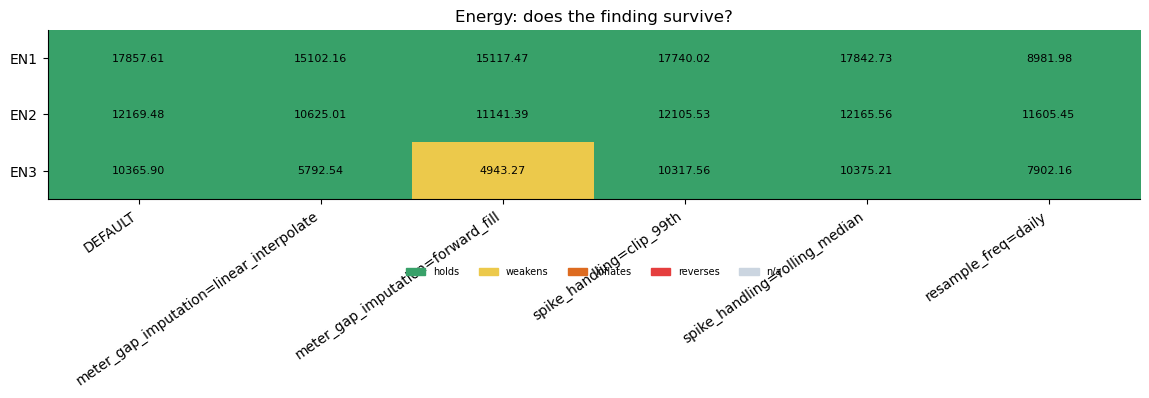

In [7]:
vals, surv = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
print(survival_summary(vals))
print(fragility_table(vals)[["finding", "worst_variant", "change", "verdict"]])
fig = heatmap(vals, title="Energy: does the finding survive?")
plt.show()